<a href="https://colab.research.google.com/github/MichalPedzisz/useful_programs/blob/main/pages/solutions/02_sol_colab/colab_intro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Colab Intro

## Sumowanie ciągu geometrycznego

Suma $n$ pierwszych wyrazów ciągu geometrycznego o pierwszym wyrazie $a_1$ oraz ilorazie $q \neq 1$ wyraża się wzorem:

$$S_n = a_1 \frac{1 - q^n}{1 - q}$$

Dla $q = 1$ suma wynosi po prostu $S_n = n \cdot a_1$. Poniżej znajduje się przykładowa implementacja tej funkcji w języku Python:

```python
def suma_geometryczna(a1: float, q: float, n: int) -> float:
    if q == 1:
        return a1 * n
    return a1 * (1 - q**n) / (1 - q)
```

In [1]:
2 + 2

4

In [2]:
import math

wynik_pi = math.pi ** math.pi
print(f"pi^pi = {wynik_pi}")

pi^pi = 36.4621596072079


In [3]:
suma_kwadratow = sum(k**2 for k in range(1, 101))
print(f"Suma kwadratów liczb od 1 do 100 wynosi: {suma_kwadratow}")

Suma kwadratów liczb od 1 do 100 wynosi: 338350


In [4]:
import os

nazwa_pliku = "colab_wynik.txt"
with open(nazwa_pliku, "w", encoding="utf-8") as f:
    f.write(f"Suma kwadratów liczb od 1 do 100: {suma_kwadratow}\n")

sciezka_pliku = os.path.abspath(nazwa_pliku)
print(f"Plik został zapisany pod ścieżką: {sciezka_pliku}")

Plik został zapisany pod ścieżką: /content/colab_wynik.txt


<>:9: SyntaxWarning: invalid escape sequence '\d'
<>:9: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_10581/1873065939.py:9: SyntaxWarning: invalid escape sequence '\d'
  ax.set_title("Wykres funkcji $y = k^2$ dla $k = 1, \dots, 20$")


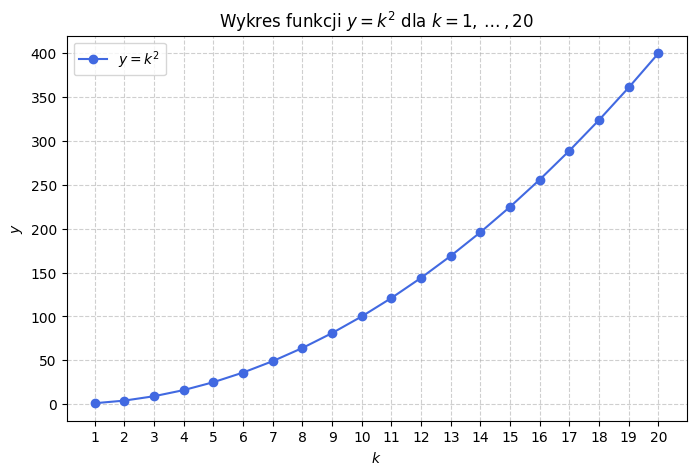

In [5]:
import matplotlib.pyplot as plt
import numpy as np

k = np.arange(1, 21)
y = k**2

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(k, y, marker="o", linestyle="-", color="royalblue", label=r"$y = k^2$")
ax.set_title("Wykres funkcji $y = k^2$ dla $k = 1, \dots, 20$")
ax.set_xlabel("$k$")
ax.set_ylabel("$y$")
ax.set_xticks(k)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend()

plt.show()

In [6]:
sciezka_wykresu = os.path.abspath("wykres.png")
fig.savefig(sciezka_wykresu, dpi=300, bbox_inches="tight")
print(f"Wykres został zapisany w: {sciezka_wykresu}")

Wykres został zapisany w: /content/wykres.png


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import Video
import os

# Parametry fizyczne wahadła (przybliżenie małych drgań)
L = 1.0          # długość nici [m]
g = 9.81         # przyspieszenie ziemskie [m/s^2]
theta0 = np.pi / 4  # kąt początkowy (45 stopni)

t = np.linspace(0, 6, 150)  # 6 sekund, 150 klatek
theta = theta0 * np.cos(np.sqrt(g / L) * t)

x = L * np.sin(theta)
y = -L * np.cos(theta)

# Konfiguracja wykresu do animacji
fig_anim, ax_anim = plt.subplots(figsize=(5, 5))
ax_anim.set_xlim(-1.3, 1.3)
ax_anim.set_ylim(-1.3, 0.3)
ax_anim.set_aspect("equal")
ax_anim.grid(True, linestyle="--", alpha=0.5)
ax_anim.set_title("Animacja wahadła matematycznego")

line, = ax_anim.plot([], [], "o-", lw=3, color="crimson", markersize=12)

def init():
    line.set_data([], [])
    return (line,)

def update(frame):
    line.set_data([0, x[frame]], [0, y[frame]])
    return (line,)

ani = FuncAnimation(fig_anim, update, frames=len(t), init_func=init, blit=True, interval=40)

# Zapis do pliku video.mp4 (ffmpeg jest domyślnie zainstalowany w Colabie)
sciezka_mp4 = os.path.abspath("video.mp4")
ani.save(sciezka_mp4, writer="ffmpeg", fps=25)
plt.close(fig_anim)  # zamykamy statyczny podgląd, aby wyświetlić tylko wideo

print(f"Wideo zostało zapisane w: {sciezka_mp4}")

# Osadzenie wideo w notatniku
Video(sciezka_mp4, embed=True)

Wideo zostało zapisane w: /content/video.mp4


Animowany GIF został zapisany w: /content/video.gif


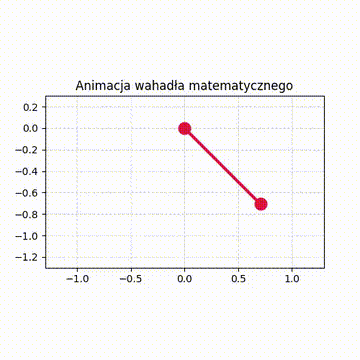

In [8]:
import subprocess
import os
from IPython.display import Image

sciezka_gif = os.path.abspath("video.gif")

# Konwersja video.mp4 -> video.gif za pomocą ffmpeg
subprocess.run(
    ["ffmpeg", "-y", "-i", "video.mp4", "-vf", "fps=15,scale=360:-1:flags=lanczos", sciezka_gif],
    check=True
)

print(f"Animowany GIF został zapisany w: {sciezka_gif}")

# Opcjonalne wyświetlenie wygenerowanego GIF-a w notatniku
Image(filename=sciezka_gif)

Wykres zapisano w: /content/parametric_curve.png


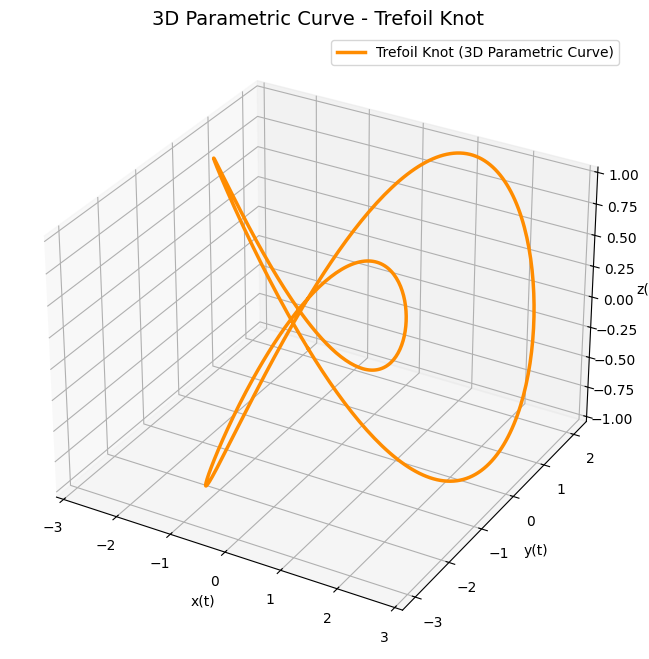

In [9]:
# Correcting the label for rendering issue in matplotlib mathtext
import os
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Parametric equations (zmodyfikowane równania - węzeł trójlistny / Trefoil Knot)
t = np.linspace(0, 2 * np.pi, 500)
x = np.sin(t) + 2 * np.sin(2 * t)
y = np.cos(t) - 2 * np.cos(2 * t)
z = -np.sin(3 * t)

# 3D Plot
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, label="Trefoil Knot (3D Parametric Curve)", color="darkorange", lw=2.5)
ax.set_title("3D Parametric Curve - Trefoil Knot", fontsize=14)
ax.set_xlabel("x(t)")
ax.set_ylabel("y(t)")
ax.set_zlabel("z(t)")
ax.legend()

# Zapis wykresu do pliku parametric_curve.png
sciezka_param = os.path.abspath("parametric_curve.png")
fig.savefig(sciezka_param, dpi=300, bbox_inches="tight")
print(f"Wykres zapisano w: {sciezka_param}")

plt.show()